# County life expectancy: outliers after noise correction

A county with high life expectancy among residents in the bottom income quartile can rank near the top because its measured covariates are favourable, because an unmeasured local factor matters, or because its life-expectancy estimate is noisy. The published county ranking does not separate those mechanisms. This case fits conditional tail models (quantile regressions of the outcome on the covariates, one per tail), corrects the ranking for published sampling uncertainty, and then tests whether the same deviations recur in a later period.

The outcome and local covariates come from the Health Inequality Project tables used by Chetty et al. {cite:p}`chetty2016inequality`. The target is a screen for places worth investigating, not an estimate of a county policy effect.

The question is how to rank area-level deviations after accounting for known sampling
noise. The workflow validates the data merge, fits both tails, compares corrected and
naive lists, and checks later data.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | counties with life expectancy above the fitted conditional tail after sampling-noise correction |
| **Observed response** | `le_raceadj_q1_M`, race-adjusted life expectancy for men in the bottom quartile |
| **Estimand** | the conditional quantile of life expectancy given county characteristics — an outlier is a county above it |
| **Units** | years of life expectancy |
| **Sampling unit** | one county |
| **Dependence** | spatial, and the outcome is again a noisy estimate |
| **Split / resampling unit** | the county |
| **Tuning** | fixed `mstop` |
| **Uncertainty** | published outcome standard errors determine reliability shrinkage; later-period tail exceedances assess persistence |
| **Claim type** | descriptive. A county on the list is not shown to have done anything |
:::


In [1]:
import json
import pathlib

import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

HERE = pathlib.Path.cwd()
results = json.loads((HERE / "county_positive_deviance.json").read_text())
raw = mb.datasets.hip_county()

n_counties = raw.height
n_eligible = results["outcomes"]["M"]["n_population_eligible"]
validation_delta = results["input_validation"]["maximum_absolute_difference"]
print(f"{n_counties} complete-case counties; {n_eligible} meet the population cutoff")
print(f"maximum difference from a printed eTable-9 correlation: {validation_delta:.4f}")

935 complete-case counties; 266 meet the population cutoff
maximum difference from a printed eTable-9 correlation: 0.0049


## Data merge and check against the published correlations

Tables `11` and `12` are joined by county Federal Information Processing Standards (FIPS) code. Before any model is fitted, the validator recomputes every gender-by-quartile correlation printed in supplement `eTable 9` using the paper's county-population weights. All {eval}`results['input_validation']['correlations_reproduced']` correlations reproduce to the printed precision; the largest absolute difference before rounding is {eval}`f"{validation_delta:.4f}"`.

Complete cases leave {eval}`n_counties` counties, of which {eval}`n_eligible` have at least the prespecified population cutoff. The cutoff applies only to the final ranking. Keeping smaller counties in the fit preserves information about the conditional surface while preventing their noisier estimates from becoming headline candidates.

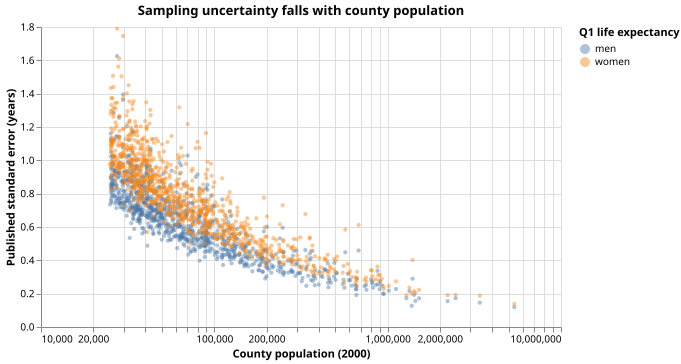

In [2]:
uncertainty = raw.select([
    "cty_pop2000", "sd_le_raceadj_q1_M", "sd_le_raceadj_q1_F"
]).unpivot(
    index="cty_pop2000", variable_name="outcome", value_name="standard error"
).with_columns(
    pl.col("outcome").replace({
        "sd_le_raceadj_q1_M": "men",
        "sd_le_raceadj_q1_F": "women",
    })
)

alt.Chart(uncertainty, title="Sampling uncertainty falls with county population").mark_circle(
    size=18, opacity=0.45
).encode(
    x=alt.X("cty_pop2000:Q", title="County population (2000)", scale=alt.Scale(type="log")),
    y=alt.Y("standard error:Q", title="Published standard error (years)"),
    color=alt.Color("outcome:N", title="Q1 life expectancy"),
).properties(width=520, height=300)

The sampling error is largest where population is smallest. Ranking raw residuals would therefore give counties with imprecise outcomes more opportunities to enter either tail. Three corrections address distinct parts of that problem:

- The model loss uses weights proportional to `1 / s_i^2`, where `s_i` is the published standard error.
- Candidate lists exclude counties below the population cutoff, even though those counties remain in the fit.
- A residual `r_i` is multiplied by its reliability, `tau^2 / (tau^2 + s_i^2)`. The scalar `tau^2` maximises the likelihood of the residuals from a cross-validated Gaussian mean fit under variance `tau^2 + s_i^2`.

The reliability calculation is empirical-Bayes shrinkage, which pulls each residual toward zero by an amount that grows with the published standard error. It reduces a large residual more when the published estimate is imprecise; it does not create additional information about that county.

## Quantile models for the tails

The learner menu matches the commuting-zone case: each standardized covariate offers a linear learner and a centred penalised spline at equal degrees of freedom, followed by a spatial surface and census-division effect. `Quantile(tau=0.1)`, `Quantile(tau=0.5)`, and `Quantile(tau=0.9)` are tuned by separate bootstrap risk curves because one stopping iteration cannot be assumed optimal for every tail.

The next cell refits the corrected male lower- and upper-tail models at the selected stopping iterations. The fits run live; only the bootstrap risk curves are loaded from saved output.

In [3]:
COVARIATES = results["covariate_names"]
frame = raw.with_columns([
    ((pl.col(column) - pl.col(column).mean()) / pl.col(column).std()).alias(column)
    for column in COVARIATES
])
data = {column: frame[column].to_numpy() for column in frame.columns}
data["census_division"] = frame["census_div"].cast(str).to_numpy()
terms = [item for column in COVARIATES for item in (
    f"bols({column}, intercept=False)", f"bbs({column}, center=True, df=1)"
)] + ["bspatial(lon, lat, df=6)", "brandom(census_division)"]
formula = "le_raceadj_q1_M ~ " + " + ".join(terms)
weights = 1.0 / frame["sd_le_raceadj_q1_M"].to_numpy() ** 2
weights /= weights.min()

tail_models = {}
for tau, key in ((0.1, "q10"), (0.9, "q90")):
    mstop = results["outcomes"]["M"]["models"]["corrected"][key]["mstop"]
    tail_models[tau] = mb.gamboost(
        formula, data=data, family=mb.Quantile(tau=tau), weights=weights,
        control=mb.boost_control(mstop, 0.1),
    )
print({tau: model.mstop for tau, model in tail_models.items()})

/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 1 learner(s): brandom(brandom(census_division)): 6.44 of 8 df after 66 selections (one step: 2.48). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


{0.1: 3556, 0.9: 4206}


In [4]:
tau2 = results["outcomes"]["M"]["excess_variance_tau2"]
s2 = frame["sd_le_raceadj_q1_M"].to_numpy() ** 2
reliability = tau2 / (tau2 + s2)
eligible = frame["cty_pop2000"].to_numpy() >= results["population_cutoff"]
observed = frame["le_raceadj_q1_M"].to_numpy()
# Evaluate the fitted model on the study's declared rows or prediction grid.
def live_ranking(tau, direction):
    signed = observed - np.asarray(tail_models[tau].predict())
    score = signed if direction == "positive" else -signed
    order = np.flatnonzero(eligible)[np.argsort(-(reliability * score)[eligible])][:5]
    return pl.DataFrame({
        "direction": direction,
        "county": [f"{frame['county_name'][int(i)]}, {frame['stateabbrv'][int(i)]}" for i in order],
        "observed": observed[order],
        "fitted tail": np.asarray(tail_models[tau].predict())[order],
        "reliability": reliability[order],
        "shrunk score": (reliability * score)[order],
    })

live = pl.concat([live_ranking(0.9, "positive"), live_ranking(0.1, "negative")])
stored_labels = {direction: [row["label"] for row in
                 results["outcomes"]["M"]["rankings"]["corrected"][direction][:5]]
                 for direction in ("positive", "negative")}
live_overlap = {}
for direction in stored_labels:
    live_labels = live.filter(pl.col("direction") == direction)["county"].to_list()
    live_overlap[direction] = len(set(live_labels) & set(stored_labels[direction]))
    assert live_overlap[direction] >= 4
minimum_live_overlap = min(live_overlap.values())
display(live.with_columns(pl.col(pl.Float64).round(3)))


direction,county,observed,fitted tail,reliability,shrunk score
str,str,f64,f64,f64,f64
"""positive""","""Collin, TX""",79.708,78.224,0.625,0.927
"""positive""","""Kane, IL""",78.948,78.018,0.69,0.642
"""positive""","""Utah, UT""",78.946,78.094,0.541,0.461
"""positive""","""Rapides, LA""",76.559,75.907,0.583,0.38
"""positive""","""San Juan, NM""",77.713,76.92,0.475,0.377
"""negative""","""Rensselaer, NY""",74.8,75.847,0.586,0.614
"""negative""","""Ector, TX""",73.114,73.793,0.56,0.38
"""negative""","""Dauphin, PA""",74.819,75.301,0.692,0.334
"""negative""","""Shawnee, KS""",73.725,74.207,0.629,0.303


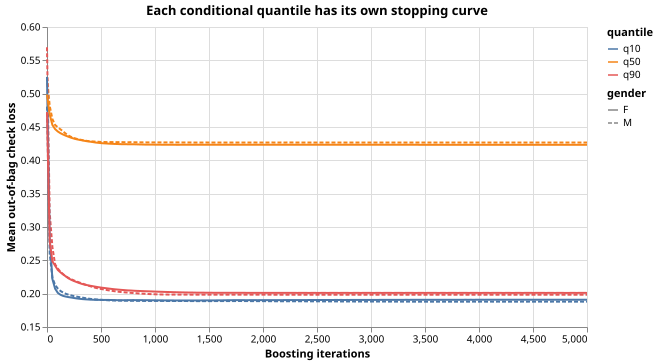

In [5]:
curve_rows = []
for gender in ("M", "F"):
    for key in ("q10", "q50", "q90"):
        model = results["outcomes"][gender]["models"]["corrected"][key]
        curve_rows.extend({
            "gender": gender, "quantile": key, **point,
            "optimal": point["mstop"] == model["mstop"],
        } for point in model["cv_curve"])
curves = pl.DataFrame(curve_rows)

alt.Chart(curves, title="Each conditional quantile has its own stopping curve").mark_line().encode(
    x=alt.X("mstop:Q", title="Boosting iterations"),
    y=alt.Y("risk:Q", title="Mean out-of-bag check loss", scale=alt.Scale(zero=False)),
    color=alt.Color("quantile:N", title="quantile"),
    strokeDash=alt.StrokeDash("gender:N", title="gender"),
).properties(width=540, height=300)

All tail optima are inside their fitted paths. The live refit retains at least {eval}`minimum_live_overlap` of each stored top five; one marginal name can switch after thousands of non-smooth updates. The leading names are stable, but the boundary is not bitwise invariant.

The reliability correction is substantial: the median reliability is lower for women than for men, so an equally large observed residual is shrunk more in the women's ranking.

In [6]:
comparison_rows = []
for gender, outcome in results["outcomes"].items():
    comparison_rows.append({
        "gender": "men" if gender == "M" else "women",
        "excess SD (years)": outcome["excess_sd"],
        "median reliability": outcome["reliability"]["median"],
        "naive/corrected positive overlap": outcome["comparisons"]["naive_vs_corrected_positive_top10"],
        "naive/corrected negative overlap": outcome["comparisons"]["naive_vs_corrected_negative_top10"],
        "quantile/Gaussian positive overlap": outcome["comparisons"]["quantile_vs_gaussian_positive_top10"],
        "quantile/Gaussian negative overlap": outcome["comparisons"]["quantile_vs_gaussian_negative_top10"],
        "conditional/published positive overlap": outcome["comparisons"]["conditional_positive_in_published_unconditional_top10"],
        "conditional/published negative overlap": outcome["comparisons"]["conditional_negative_in_published_unconditional_bottom10"],
    })
comparisons = pl.DataFrame(comparison_rows)
max_naive_overlap = int(comparisons.select(
    pl.max_horizontal("naive/corrected positive overlap", "naive/corrected negative overlap")
).max().item())
display(comparisons.with_columns(pl.col(pl.Float64).round(2)))

gender,excess SD (years),median reliability,naive/corrected positive overlap,naive/corrected negative overlap,quantile/Gaussian positive overlap,quantile/Gaussian negative overlap,conditional/published positive overlap,conditional/published negative overlap
str,f64,f64,i64,i64,i64,i64,i64,i64
"""men""",0.5,0.37,0,2,5,5,0,0
"""women""",0.41,0.21,1,1,6,8,0,0


## Naive and noise-corrected outlier lists

The naive and corrected lists share at most {eval}`max_naive_overlap` names in any gender-by-direction top ten. None of the corrected conditional candidates appears in the supplement's unconditional top or bottom list. Conditioning changes the question from “where is life expectancy high or low?” to “where is it unexpectedly high or low after these measured covariates?”

The corrected quantile and Gaussian lists retain several common counties, especially for women, but they are not identical. The quantile fits therefore add information about tail asymmetry without replacing the more stable Gaussian residual screen.

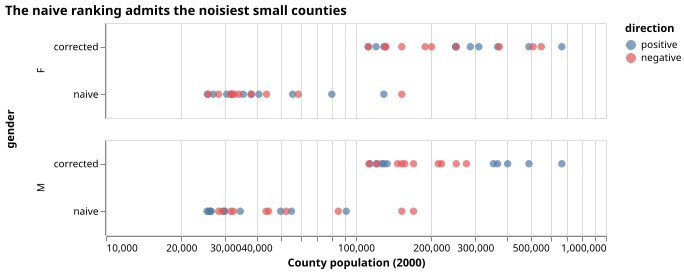

In [7]:
population_rows = []
for gender, outcome in results["outcomes"].items():
    for spec in ("naive", "corrected"):
        for direction in ("positive", "negative"):
            population_rows.extend({
                "gender": gender, "specification": spec, "direction": direction,
                "population": row["population_2000"], "county": row["label"],
            } for row in outcome["rankings"][spec][direction][:10])
population_ranks = pl.DataFrame(population_rows)

alt.Chart(population_ranks, title="The naive ranking admits the noisiest small counties").mark_circle(
    size=55, opacity=0.7
).encode(
    x=alt.X("population:Q", title="County population (2000)", scale=alt.Scale(type="log")),
    y=alt.Y("specification:N", title=None),
    color=alt.Color("direction:N", scale=alt.Scale(domain=["positive", "negative"], range=["#4e79a7", "#e15759"])),
    row=alt.Row("gender:N", title="gender"),
    tooltip=["county:N", alt.Tooltip("population:Q", format=",")],
).properties(width=500, height=95)

## Map of corrected candidates

The spatial learner uses each county's commuting-zone centroid because the Health Inequality Project files do not publish county coordinates. The map does not use those approximate points: it joins candidate FIPS codes to the Census Bureau's 2010 county cartographic boundaries. The distinction prevents two counties in one commuting zone from being drawn at the same location.

In [8]:
states = json.loads((HERE.parent / "data" / "us-states.geo.json").read_text())

county_geo = json.loads((HERE.parent / "data" / "us-counties.geo.json").read_text())

geometry = {feature["properties"]["cty"]: feature for feature in county_geo["features"]}

land = alt.Chart(alt.Data(values=states["features"])).mark_geoshape(
    fill="#f4f3f0", stroke="white", strokeWidth=0.4
).project(type="albersUsa")


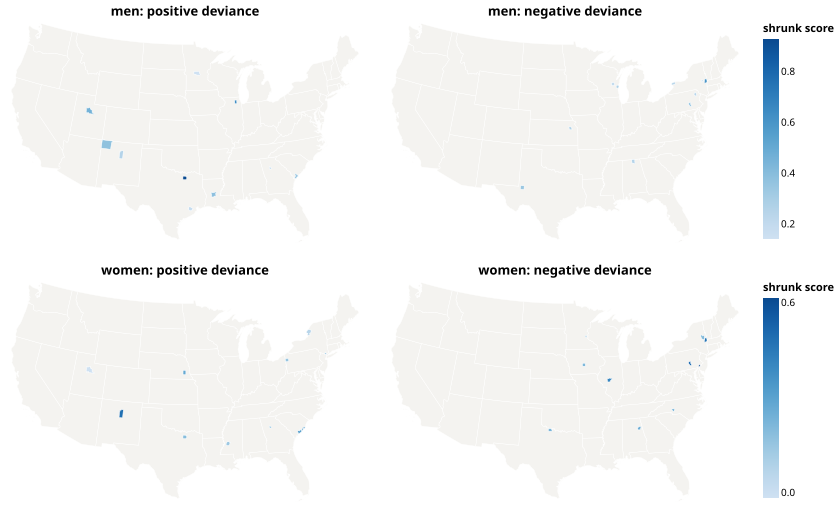

In [9]:
def deviance_map(gender, direction):
    rows = results["outcomes"][gender]["rankings"]["corrected"][direction][:10]
    features = []
    for row in rows:
        feature = json.loads(json.dumps(geometry[row["cty"]]))
        feature["properties"].update(
            label=row["label"], score=row["shrunk_deviance_score"],
            reliability=row["reliability"],
        )
        features.append(feature)
    source = alt.Data(
        values={"type": "FeatureCollection", "features": features},
        format=alt.DataFormat(property="features"),
    )
    scheme = "blues" if direction == "positive" else "reds"
    candidates = alt.Chart(source).mark_geoshape(stroke="white", strokeWidth=0.5).encode(
        color=alt.Color("properties.score:Q", title="shrunk score", scale=alt.Scale(scheme=scheme)),
        tooltip=[
            alt.Tooltip("properties.label:N", title="county"),
            alt.Tooltip("properties.score:Q", title="shrunk score", format=".2f"),
            alt.Tooltip("properties.reliability:Q", title="reliability", format=".2f"),
        ],
    ).project(type="albersUsa")
    label = "men" if gender == "M" else "women"
    return (land + candidates).properties(width=360, height=220, title=f"{label}: {direction} deviance")
# Read the recorded experiment instead of rerunning its expensive fits.
alt.vconcat(
    alt.hconcat(deviance_map("M", "positive"), deviance_map("M", "negative")),
    alt.hconcat(deviance_map("F", "positive"), deviance_map("F", "negative")),
).resolve_scale(color="independent")


The candidate counties do not form one regional cluster. That dispersion is compatible with local omitted factors, but a map of one pooled-period estimate cannot distinguish a persistent local process from selection on a noisy tail. The temporal check assesses whether the conditional deviations persist.

## Validation on later data

County estimates are available only for the pooled period. The public annual file covers the largest commuting zones, so the validation fits the same conditional tail model on inverse-variance averages from the earlier half of the period and evaluates the fitted surface on the later half. Only commuting zones complete on the same covariate menu enter. A common later-period longevity shift is removed before relative deviations are compared.

The period standard errors assume independent annual estimates because their covariance is not published. This approximation affects reliability magnitudes, not which raw annual estimates enter each period average.

In [10]:
temporal_rows = []
for gender, outcome in results["temporal_validation"]["outcomes"].items():
    for direction in ("positive", "negative"):
        item = outcome[direction]
        temporal_rows.append({
            "gender": "men" if gender == "M" else "women",
            "direction": direction,
            "complete CZs": outcome["n_cz"],
            "rank correlation": item["spearman_all_scores"],
            "top-10 overlap": item["top10_overlap"],
            "late tail signs among early top 10": item["late_tail_sign_persistence_in_early_top10"],
            "persistent names": ", ".join(item["persistent_top10"]),
        })
temporal = pl.DataFrame(temporal_rows)
display(temporal.with_columns(pl.col("rank correlation").round(2)))

gender,direction,complete CZs,rank correlation,top-10 overlap,late tail signs among early top 10,persistent names
str,str,i64,f64,i64,i64,str
"""men""","""positive""",56,0.59,3,4,"""Spokane, WA, Portland, ME, Man…"
"""men""","""negative""",56,0.5,4,5,"""San Antonio, TX, Des Moines, I…"
"""women""","""positive""",56,0.6,2,4,"""Erie, PA, Mobile, AL"""
"""women""","""negative""",56,0.42,2,3,"""Oklahoma City, OK, Minneapolis…"


The score correlations remain positive, so the conditional ordering is not pure noise. The top-ten overlap is nevertheless small in every panel, and fewer than half of most early candidates remain beyond the same fitted tail after the common time shift. The corrected county names are therefore hypotheses for qualitative follow-up, not durable labels of exceptional performance.

## Limitations

The model is ecological: a county association does not identify an individual or policy effect. Counties below the source reporting threshold are absent, so the analysis says little about rural America. Complete-case filtering changes the published-table population, covariates come from different vintages, and the spatial adjustment has commuting-zone rather than county resolution.

Reliability shrinkage accounts for the published outcome standard error but not uncertainty from variable selection, stopping-iteration choice, or the fitted conditional surface. Ranking a fitted residual still selects on the outcome and will regress toward zero on re-estimation; the weak temporal overlap measures that consequence directly. A follow-up study should acquire county estimates by subperiod, preregister a smaller candidate set, and investigate mechanisms without treating this screen as causal evidence.

```{bibliography}
:filter: docname in docnames
```